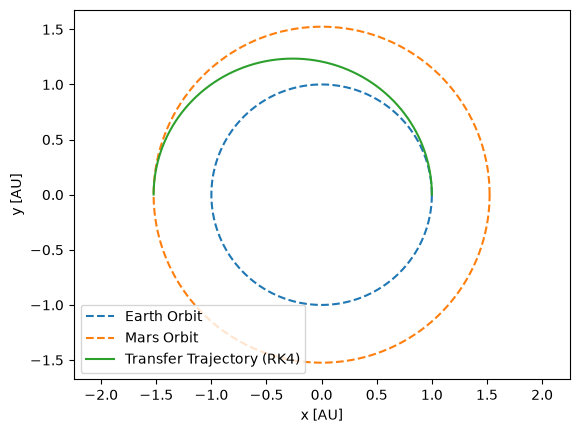

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Dimensionless canonical units: G * M_sun = 1, r_Earth = 1 AU, T_Earth = 2 * pi
mu = 1.0
r_e, r_m = 1.0, 1.524

def equations_of_motion(state):
    x, y, vx, vy = state
    r = np.hypot(x, y)
    ax = -mu * x / r**3
    ay = -mu * y / r**3
    return np.array([vx, vy, ax, ay])

def rk4_step(f, state, dt):
    k1 = f(state)
    k2 = f(state + 0.5 * dt * k1)
    k3 = f(state + 0.5 * dt * k2)
    k4 = f(state + dt * k3)
    return state + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

# Hohmann transfer initial boundary conditions
a_trans = 0.5 * (r_e + r_m)
v_init = np.sqrt(mu * (2.0 / r_e - 1.0 / a_trans))
t_trans = np.pi * np.sqrt(a_trans**3 / mu)

dt = 1e-3
steps = int(t_trans / dt)
traj = np.zeros((steps, 4))
traj[0] = [r_e, 0.0, 0.0, v_init]

for i in range(1, steps):
    traj[i] = rk4_step(equations_of_motion, traj[i - 1], dt)

theta = np.linspace(0, 2 * np.pi, 300)
plt.plot(r_e * np.cos(theta), r_e * np.sin(theta), '--', label='Earth Orbit')
plt.plot(r_m * np.cos(theta), r_m * np.sin(theta), '--', label='Mars Orbit')
plt.plot(traj[:, 0], traj[:, 1], '-', label='Transfer Trajectory (RK4)')
plt.axis('equal')
plt.xlabel('x [AU]')
plt.ylabel('y [AU]')
plt.legend()
plt.show()
